In [1]:
%pip install -q qiskit==2.6.1 qiskit-machine-learning==0.9.1 scikit-learn==1.6.1 numpy==2.1.3 pandas==2.2.3 scipy==1.16.3 matplotlib pylatexenc

In [2]:
import json
import time
import pylatexenc
import pandas as pd
import numpy as np
from collections import Counter
from scipy.stats import binomtest


from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score,  f1_score, classification_report, confusion_matrix


from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityQuantumKernel

In [3]:
# Download CB513 dataset
url = "https://huggingface.co/datasets/proteinea/secondary_structure_prediction/resolve/main/CB513.csv"

df = pd.read_csv(url)

# Inspect dataset
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (511, 5)

Column names:
['input', 'dssp3', 'dssp8', 'disorder', 'cb513_mask']

First 5 rows:


,input,dssp3,dssp8,disorder,cb513_mask
0,RTDCYGNVNRIDTTGASCKTAKPEGLSYCGVSASKKIAERDLQAMD...,CCCCCCCHHHCCCCCECHHHHCCCCCCCCEHHHHHHHHHHCHHHHH...,CCCTTCCGGGSCCCCBCHHHHTTTTCSCCBHHHHHHHHHHTHHHHH...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
1,GKITFYEDRGFQGRHYECSSDHSNLQPYFSRCNSIRVDSGCWMLYE...,CEEEEEEECCCEEEEEEECCCECCCCCCCCCCCEEEEEECEEEEEC...,CEEEEEEETTTEEEEEEECSCBSCCTTTCSCCSEEEEEESEEEEES...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
2,MFKVYGYDSNIHKCVYCDNAKRLLTVKKQPFEFINIMPEKGVFDDE...,CEEEEECCCCCCCCHHHHHHHHHHHHCCCCEEEEECCCECCECCHH...,CEEEEECCTTTSCCHHHHHHHHHHHHTTCCEEEEESCSBTTBCCHH...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
3,APAFSVSPASGASDGQSVSVSVAAAGETYYIAQCAPVGGQDACNPA...,CCEEEEECCCCCCCCCEEEEEEECCCCEEEEEEECEECCEECCCCC...,CCEEEEECCSSCCSSCEEEEEEESCCSEEEEEEECEETTEECCCTT...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
4,TPAFNKPKVELHVHLDGAIKPETILYFGKKRGIALPADTVEELRNI...,CCCCCCCEEEEEEEHHHCCCHHHHHHHHHHHCCCCCCCCHHHHHHH...,CCSCCSCEEEEEEEGGGSCCHHHHHHHHHHHTCCCSCSSHHHHHHH...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....


In [4]:
# Check sequence and label lengths
df["sequence_length"] = df["input"].str.len()
df["label_length"] = df["dssp3"].str.len()

print("Number of proteins:", len(df))

print("Sequence and label lengths match:",
      (df["sequence_length"] == df["label_length"]).all())

print("\nSequence length statistics:")
print(df["sequence_length"].describe())

# Count Q3 secondary structure labels
label_counts = Counter("".join(df["dssp3"]))

print("\nQ3 class distribution:")
for label, count in sorted(label_counts.items()):
    print(f"{label}: {count:,} residues")

print("\nUnique Q3 labels:", sorted(label_counts.keys()))


Number of proteins: 511
Sequence and label lengths match: True

Sequence length statistics:
count    511.000000
mean     281.821918
std      193.408897
min       20.000000
25%      128.000000
50%      238.000000
75%      394.500000
max      874.000000
Name: sequence_length, dtype: float64

Q3 class distribution:
C: 63,084 residues
E: 31,921 residues
H: 49,006 residues

Unique Q3 labels: ['C', 'E', 'H']


In [5]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Training proteins:", len(train_df))
print("Testing proteins:", len(test_df))

print("Training residues:", train_df["sequence_length"].sum())
print("Testing residues:", test_df["sequence_length"].sum())

# Verify no row indices overlap
assert set(train_df.index).isdisjoint(set(test_df.index))

print("Protein row split successful!")


Training proteins: 408
Testing proteins: 103
Training residues: 115378
Testing residues: 28633
Protein row split successful!


In [6]:
# Approximate amino acid properties:
# hydrophobicity, molecular weight, polarity, charge, aromaticity
aa_properties = {
    "A": [1.8, 89.1, 0, 0, 0],
    "R": [-4.5, 174.2, 1, 1, 0],
    "N": [-3.5, 132.1, 1, 0, 0],
    "D": [-3.5, 133.1, 1, -1, 0],
    "C": [2.5, 121.2, 1, 0, 0],
    "Q": [-3.5, 146.2, 1, 0, 0],
    "E": [-3.5, 147.1, 1, -1, 0],
    "G": [-0.4, 75.1, 0, 0, 0],
    "H": [-3.2, 155.2, 1, 0, 1],
    "I": [4.5, 131.2, 0, 0, 0],
    "L": [3.8, 131.2, 0, 0, 0],
    "K": [-3.9, 146.2, 1, 1, 0],
    "M": [1.9, 149.2, 0, 0, 0],
    "F": [2.8, 165.2, 0, 0, 1],
    "P": [-1.6, 115.1, 0, 0, 0],
    "S": [-0.8, 105.1, 1, 0, 0],
    "T": [-0.7, 119.1, 1, 0, 0],
    "W": [-0.9, 204.2, 0, 0, 1],
    "Y": [-1.3, 181.2, 1, 0, 1],
    "V": [4.2, 117.1, 0, 0, 0],
}

# Unknown or padding residue
aa_properties["X"] = [0, 0, 0, 0, 0]

def extract_features(dataframe, window_size=5):
    half = window_size // 2
    X, y = [], []

    for _, row in dataframe.iterrows():
        sequence = row["input"]
        labels = row["dssp3"]

        # NEW: Parse the CB513 mask
        mask = np.fromstring(row["cb513_mask"], sep=" ")

        # NEW: Verify alignment
        assert len(sequence) == len(labels) == len(mask)

        padded = "X" * half + sequence + "X" * half

        for i, label in enumerate(labels):

            # NEW: Skip excluded residues
            if mask[i] != 1.0:
                continue

            window = padded[i:i + window_size]

            features = []
            for aa in window:
                features.extend(
                    aa_properties.get(aa, aa_properties["X"])
                )

            X.append(features)
            y.append(label)

    return np.array(X, dtype=np.float32), np.array(y)


X_train_raw, y_train = extract_features(train_df)
X_test_raw, y_test = extract_features(test_df)

print("Training feature shape:", X_train_raw.shape)
print("Testing feature shape:", X_test_raw.shape)
print("Training labels:", Counter(y_train))
print("Testing labels:", Counter(y_test))

# NEW: Validate total number of included residues
total_residues = len(y_train) + len(y_test)

print("\nTotal included residues:", total_residues)

assert total_residues == 83991, "Unexpected residue count!"

print("Mask filtering successful!")

Training feature shape: (66397, 25)
Testing feature shape: (17594, 25)
Training labels: Counter({np.str_('C'): 28550, np.str_('H'): 23187, np.str_('E'): 14660})
Testing labels: Counter({np.str_('C'): 7649, np.str_('H'): 5915, np.str_('E'): 4030})

Total included residues: 83991
Mask filtering successful!


In [7]:
rng = np.random.default_rng(42)

def balanced_sample_indices(y, n_per_class):
    indices = []
    for label in ["C", "E", "H"]:
        candidates = np.where(y == label)[0]
        selected = rng.choice(
            candidates, size=n_per_class, replace=False
        )
        indices.extend(selected)
    return np.array(indices)

# Select balanced samples
train_idx = balanced_sample_indices(y_train, 60)
test_idx = balanced_sample_indices(y_test, 30)

X_train_small = X_train_raw[train_idx]
X_test_small = X_test_raw[test_idx]

y_train_small = y_train[train_idx]
y_test_small = y_test[test_idx]

# Fit preprocessing only on training samples
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_small)
X_test_scaled = scaler.transform(X_test_small)

pca = PCA(n_components=4, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Scale quantum feature angles into [0, pi]
# Clip values outside the training-fitted range
angle_scaler = MinMaxScaler(
    feature_range=(0, np.pi),
    clip=True
)

X_train_q = angle_scaler.fit_transform(X_train_pca)
X_test_q = angle_scaler.transform(X_test_pca)

print("Training range:", X_train_q.min(), X_train_q.max())
print("Testing range:", X_test_q.min(), X_test_q.max())


print("Quantum training shape:", X_train_q.shape)
print("Quantum testing shape:", X_test_q.shape)
print("PCA explained variance:",
      round(pca.explained_variance_ratio_.sum(), 4))

print("Training classes:",
      np.unique(y_train_small, return_counts=True))
print("Testing classes:",
      np.unique(y_test_small, return_counts=True))


Training range: 0.0 3.1415927
Testing range: 0.0 3.1415927
Quantum training shape: (180, 4)
Quantum testing shape: (90, 4)
PCA explained variance: 0.365
Training classes: (array(['C', 'E', 'H'], dtype='<U1'), array([60, 60, 60]))
Testing classes: (array(['C', 'E', 'H'], dtype='<U1'), array([30, 30, 30]))


Number of qubits: 4
Number of parameters: 4
Circuit depth: 19


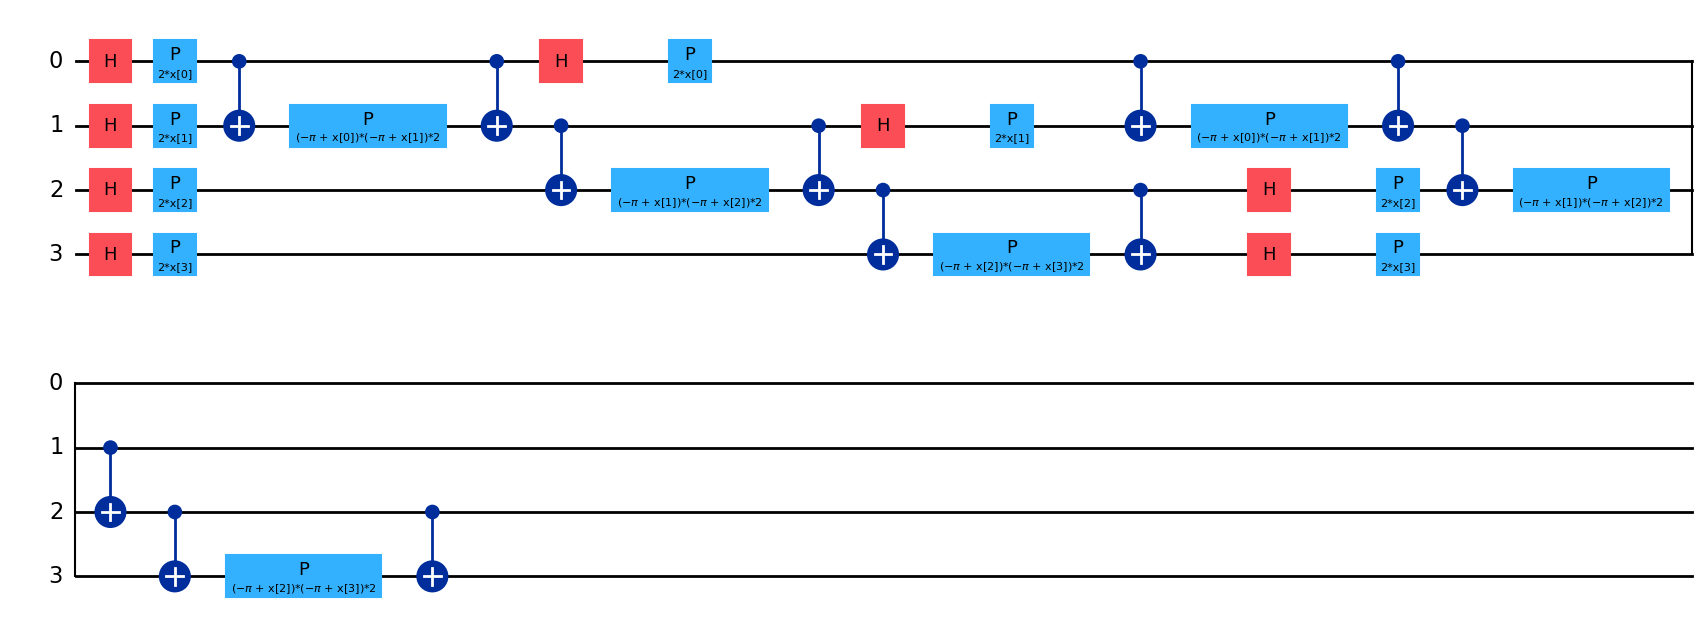

Quantum fidelity kernel initialized successfully!


In [8]:
# Build a 4-qubit quantum feature map
feature_map = zz_feature_map(
    feature_dimension=4,
    reps=2,
    entanglement="linear"
)

print("Number of qubits:", feature_map.num_qubits)
print("Number of parameters:", feature_map.num_parameters)
print("Circuit depth:", feature_map.depth())

# Display the circuit
display(feature_map.draw(output="mpl"))

# Initialize the quantum fidelity kernel
qkernel = FidelityQuantumKernel(
    feature_map=feature_map
)

print("Quantum fidelity kernel initialized successfully!")

In [9]:
# Training kernel
start = time.time()

K_train_q = qkernel.evaluate(
    x_vec=X_train_q
)

train_time = time.time() - start

print("Training kernel shape:", K_train_q.shape)
print("Training kernel time:", round(train_time, 2), "seconds")

# Testing kernel
start = time.time()

K_test_q = qkernel.evaluate(
    x_vec=X_test_q,
    y_vec=X_train_q
)

test_time = time.time() - start

print("Testing kernel shape:", K_test_q.shape)
print("Testing kernel time:", round(test_time, 2), "seconds")

# Save results to avoid recomputation
np.savez_compressed(
    "protein_quantum_kernels.npz",
    K_train_q=K_train_q,
    K_test_q=K_test_q
)

Training kernel shape: (180, 180)
Training kernel time: 163.91 seconds
Testing kernel shape: (90, 180)
Testing kernel time: 138.28 seconds
Quantum kernel matrices saved successfully!


In [10]:
# Train multiclass SVM using the quantum kernel
qsvm = SVC(
    kernel="precomputed",
    decision_function_shape="ovo",
    C=1.0
)

start = time.time()

qsvm.fit(K_train_q, y_train_small)

training_time = time.time() - start

# Predict using the testing quantum kernel
y_pred_q = qsvm.predict(K_test_q)

# Evaluate performance
accuracy_q = accuracy_score(y_test_small, y_pred_q)

print("Quantum SVM Results")
print("-------------------")
print("Training time:", round(training_time, 4), "seconds")
print("Test accuracy:", round(accuracy_q, 4))

print("\nClassification Report:")
print(classification_report(
    y_test_small,
    y_pred_q,
    labels=["C", "E", "H"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_small,
    y_pred_q,
    labels=["C", "E", "H"]
))


Quantum SVM Results
-------------------
Training time: 0.0044 seconds
Test accuracy: 0.5

Classification Report:
              precision    recall  f1-score   support

           C       0.48      0.53      0.51        30
           E       0.47      0.53      0.50        30
           H       0.57      0.43      0.49        30

    accuracy                           0.50        90
   macro avg       0.51      0.50      0.50        90
weighted avg       0.51      0.50      0.50        90


Confusion Matrix:
[[16  9  5]
 [ 9 16  5]
 [ 8  9 13]]


In [11]:
# Classical SVM with RBF kernel
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.01, 0.1, 1, 10, "scale"]
}

grid = GridSearchCV(
    SVC(kernel="rbf"),
    param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

start = time.time()

grid.fit(X_train_q, y_train_small)

classical_time = time.time() - start

best_svm = grid.best_estimator_
y_pred_classical = best_svm.predict(X_test_q)

accuracy_classical = accuracy_score(
    y_test_small,
    y_pred_classical
)

print("Classical RBF SVM Results")
print("-------------------------")
print("Best parameters:", grid.best_params_)
print("Training + tuning time:",
      round(classical_time, 4), "seconds")
print("Test accuracy:",
      round(accuracy_classical, 4))

print("\nClassification Report:")
print(classification_report(
    y_test_small,
    y_pred_classical,
    labels=["C", "E", "H"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_small,
    y_pred_classical,
    labels=["C", "E", "H"]
))


Classical RBF SVM Results
-------------------------
Best parameters: {'C': 10, 'gamma': 10}
Training + tuning time: 2.4908 seconds
Test accuracy: 0.4222

Classification Report:
              precision    recall  f1-score   support

           C       0.40      0.33      0.36        30
           E       0.31      0.37      0.34        30
           H       0.57      0.57      0.57        30

    accuracy                           0.42        90
   macro avg       0.43      0.42      0.42        90
weighted avg       0.43      0.42      0.42        90


Confusion Matrix:
[[10 16  4]
 [10 11  9]
 [ 5  8 17]]


In [12]:
# Tune C using the existing quantum kernel
q_grid = GridSearchCV(
    SVC(kernel="precomputed"),
    param_grid={"C": [0.01, 0.1, 1, 10, 100]},
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

q_grid.fit(K_train_q, y_train_small)

# Evaluate on held-out test samples
y_pred_q_tuned = q_grid.best_estimator_.predict(K_test_q)

print("Best quantum C:", q_grid.best_params_)
print("Cross-validation macro F1:",
      round(q_grid.best_score_, 4))

print("Test accuracy:",
      round(accuracy_score(y_test_small, y_pred_q_tuned), 4))

print("Test macro F1:",
      round(f1_score(
          y_test_small,
          y_pred_q_tuned,
          average="macro"
      ), 4))

print("\nClassification Report:")
print(classification_report(
    y_test_small,
    y_pred_q_tuned,
    zero_division=0
))


Best quantum C: {'C': 1}
Cross-validation macro F1: 0.4095
Test accuracy: 0.5
Test macro F1: 0.4995

Classification Report:
              precision    recall  f1-score   support

           C       0.48      0.53      0.51        30
           E       0.47      0.53      0.50        30
           H       0.57      0.43      0.49        30

    accuracy                           0.50        90
   macro avg       0.51      0.50      0.50        90
weighted avg       0.51      0.50      0.50        90



In [13]:
# Use the same sampled residues, but retain all 25 features
X_train_25 = X_train_raw[train_idx]
X_test_25 = X_test_raw[test_idx]

pipeline = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)

grid_25 = GridSearchCV(
    pipeline,
    param_grid={
        "svc__C": [0.1, 1, 10, 100],
        "svc__gamma": [0.01, 0.1, 1, "scale"]
    },
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

grid_25.fit(X_train_25, y_train_small)

y_pred_25 = grid_25.predict(X_test_25)

print("Best parameters:", grid_25.best_params_)
print("Cross-validation macro F1:", round(grid_25.best_score_, 4))
print("Test accuracy:", round(accuracy_score(y_test_small, y_pred_25), 4))
print("Test macro F1:", round(f1_score(
    y_test_small, y_pred_25, average="macro"
), 4))

print("\nClassification Report:")
print(classification_report(
    y_test_small, y_pred_25, zero_division=0
))


Best parameters: {'svc__C': 100, 'svc__gamma': 0.01}
Cross-validation macro F1: 0.4526
Test accuracy: 0.5111
Test macro F1: 0.508

Classification Report:
              precision    recall  f1-score   support

           C       0.49      0.63      0.55        30
           E       0.57      0.43      0.49        30
           H       0.50      0.47      0.48        30

    accuracy                           0.51        90
   macro avg       0.52      0.51      0.51        90
weighted avg       0.52      0.51      0.51        90



In [15]:
def mcnemar_comparison(y_true, pred_a, pred_b, name_a, name_b):
    a_correct = np.asarray(pred_a) == np.asarray(y_true)
    b_correct = np.asarray(pred_b) == np.asarray(y_true)

    a_only = np.sum(a_correct & ~b_correct)
    b_only = np.sum(~a_correct & b_correct)

    discordant = a_only + b_only

    p_value = (
        binomtest(min(a_only, b_only), discordant, 0.5).pvalue
        if discordant > 0 else 1.0
    )

    print(f"\n{name_a} vs {name_b}")
    print(f"{name_a} only correct: {a_only}")
    print(f"{name_b} only correct: {b_only}")
    print(f"Exact McNemar p-value: {p_value:.4f}")

    return p_value

print("Available prediction variables:")
print([name for name in globals()
       if name.startswith("y_pred") or name.endswith("_pred")])

Available prediction variables:
['y_pred_q', 'y_pred_classical', 'y_pred_q_tuned', 'y_pred_25']


In [16]:
# Comparison 1: Quantum 4D vs Classical 4D
p_q_vs_4d = mcnemar_comparison(
    y_test_small,
    y_pred_q_tuned,
    y_pred_classical,
    "Quantum SVM (4D)",
    "Classical RBF SVM (4D)"
)

# Comparison 2: Quantum 4D vs Classical 25D
p_q_vs_25d = mcnemar_comparison(
    y_test_small,
    y_pred_q_tuned,
    y_pred_25,
    "Quantum SVM (4D)",
    "Classical RBF SVM (25D)"
)


Quantum SVM (4D) vs Classical RBF SVM (4D)
Quantum SVM (4D) only correct: 21
Classical RBF SVM (4D) only correct: 14
Exact McNemar p-value: 0.3105

Quantum SVM (4D) vs Classical RBF SVM (25D)
Quantum SVM (4D) only correct: 23
Classical RBF SVM (25D) only correct: 24
Exact McNemar p-value: 1.0000


In [18]:
test_protein_ids = []

for protein_id, (_, row) in enumerate(test_df.iterrows()):
    mask = np.fromstring(row["cb513_mask"], sep=" ")

    for included in mask:
        if included == 1.0:
            test_protein_ids.append(protein_id)

test_protein_ids = np.array(test_protein_ids)

sampled_protein_ids = test_protein_ids[test_idx]

protein_counts = Counter(sampled_protein_ids)

print("Feature rows aligned:",
      len(test_protein_ids) == len(X_test_raw))

print("Total sampled residues:", len(sampled_protein_ids))
print("Distinct proteins represented:", len(protein_counts))

print("Maximum sampled residues from one protein:",
      max(protein_counts.values()))

print("Proteins contributing multiple residues:",
      sum(count > 1 for count in protein_counts.values()))

Feature rows aligned: True
Total sampled residues: 90
Distinct proteins represented: 55
Maximum sampled residues from one protein: 5
Proteins contributing multiple residues: 19


In [19]:
protein_results = pd.DataFrame({
    "protein_id": sampled_protein_ids,
    "quantum_correct": (
        np.asarray(y_pred_q_tuned) == np.asarray(y_test_small)
    ).astype(int),
    "classical_4d_correct": (
        np.asarray(y_pred_classical) == np.asarray(y_test_small)
    ).astype(int),
    "classical_25d_correct": (
        np.asarray(y_pred_25) == np.asarray(y_test_small)
    ).astype(int)
})

protein_accuracy = protein_results.groupby("protein_id").mean()

print("Number of evaluated proteins:", len(protein_accuracy))

print("\nMean per-protein accuracy:")
print(protein_accuracy.mean().round(4))

print("\nQuantum minus Classical 4D:",
      round(
          (protein_accuracy["quantum_correct"] -
           protein_accuracy["classical_4d_correct"]).mean(),
          4
      ))

print("\nQuantum minus Classical 25D:",
      round(
          (protein_accuracy["quantum_correct"] -
           protein_accuracy["classical_25d_correct"]).mean(),
          4
      ))

Number of evaluated proteins: 55

Mean per-protein accuracy:
quantum_correct          0.4639
classical_4d_correct     0.4239
classical_25d_correct    0.5330
dtype: float64

Quantum minus Classical 4D: 0.04

Quantum minus Classical 25D: -0.0691


In [20]:
rng_boot = np.random.default_rng(42)

n_boot = 10000

q = protein_accuracy["quantum_correct"].to_numpy()
c4 = protein_accuracy["classical_4d_correct"].to_numpy()
c25 = protein_accuracy["classical_25d_correct"].to_numpy()

n_proteins = len(q)

bootstrap_indices = rng_boot.integers(
    0, n_proteins,
    size=(n_boot, n_proteins)
)

diff_q_c4 = (
    q[bootstrap_indices].mean(axis=1)
    - c4[bootstrap_indices].mean(axis=1)
)

diff_q_c25 = (
    q[bootstrap_indices].mean(axis=1)
    - c25[bootstrap_indices].mean(axis=1)
)

def summarize_bootstrap(name, observed, samples):
    lower, upper = np.percentile(samples, [2.5, 97.5])

    print(name)
    print(f"Observed difference: {observed:.4f}")
    print(f"95% bootstrap CI: [{lower:.4f}, {upper:.4f}]")
    print()

summarize_bootstrap(
    "Quantum 4D vs Classical 4D",
    np.mean(q - c4),
    diff_q_c4
)

summarize_bootstrap(
    "Quantum 4D vs Classical 25D",
    np.mean(q - c25),
    diff_q_c25
)

Quantum 4D vs Classical 4D
Observed difference: 0.0400
95% bootstrap CI: [-0.0973, 0.1773]

Quantum 4D vs Classical 25D
Observed difference: -0.0691
95% bootstrap CI: [-0.2409, 0.1036]

